# Perbandingan metrik evaluasi: popularity vs CBF vs ALS vs hybrid

Notebook ini menambahkan metrik yang belum dihasilkan evaluator resmi
(`src/phase2/evaluate.py`): **Precision@K** dan **F1@K**, serta melaporkan
kelima metrik dengan nama baku: Precision@K, Recall@K, F1@K, MAP@K, NDCG@K.

Prinsip yang dipegang:

1. Peringkat tidak ditulis ulang. Fungsi ranker diimpor dari evaluator beku,
   sehingga sistem yang dibandingkan adalah sistem yang dievaluasi.
2. Protokol sama dengan `models/indo_eval.json`: peringkat penuh katalog dev
   per akun, tanpa sampled negatives, 9 titik sensitivitas
   (seed 1-3 x powerlaw_s 0.9/1.1/1.3, 600 akun per titik).
3. Validasi silang: NDCG@10, Recall@10, AP@10 dari notebook harus identik
   (toleransi 1e-9) dengan nilai terkunci. Sel validasi akan gagal keras bila
   tidak cocok.


In [1]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import sys
sys.path.insert(0, str(REPO))

from src.phase2 import config
from src.phase2.evaluate import (ALPHA_GRID, evaluate_point, evaluate_ranking)
from src.phase2.generator import generate_interactions
from src.phase2.run_eval import BASE_SHAPE, EFFECTIVE_SINCE, SEEDS, S_GRID, effective_catalog
from src.phase2.split import draft_q80, split_interactions, split_catalog
from src.phase2.train_als import ALS_PARAMS, build_csr, fit_als
from notebooks.metrics_ext import METRICS

K_GRID = (5, 10, 20)
SERVING_ALPHA = 0.8   # configs/indo_serving.yaml: cf_weight
OUT_JSON = REPO / "docs/evidence/phase2/metric_comparison.json"
LOCKED = json.loads((REPO / "models/indo_eval.json").read_text())

print("K grid:", K_GRID, "| alpha grid:", ALPHA_GRID, "| serving alpha:", SERVING_ALPHA)
print("locked eval generated_at:", LOCKED["generated_at_utc"])

K grid: (5, 10, 20) | alpha grid: (0.2, 0.4, 0.6, 0.8) | serving alpha: 0.8
locked eval generated_at: 2026-10-27T03:47:18.403738+00:00


## 1. Definisi metrik

Semua metrik memakai daftar peringkat `ranked_ids` (panjang K) dan himpunan
item relevan `relevant`. Konvensi biner: item relevan yang muncul di peringkat
dihitung 1.

| Metrik | Pertanyaan yang dijawab | Rentang |
|---|---|---|
| Precision@K | Dari K item yang disajikan, berapa proporsi yang relevan? | 0-1 |
| Recall@K | Dari semua item relevan, berapa proporsi yang berhasil masuk K teratas? | 0-1 |
| F1@K | Rata-rata harmonis P@K dan R@K: keseimbangan keduanya pada cutoff sama | 0-1 |
| MAP@K | Rata-rata presisi pada setiap posisi hit, dinormalisasi min(|relevant|, K) | 0-1 |
| NDCG@K | Seperti MAP tapi diskon posisi: hit di posisi atas bernilai lebih | 0-1 |

Kapan metrik mana dipakai:

- **Precision@K** cocok saat layar punya slot tetap (feed 12 kartu): berapa
  persen slot terpakai untuk barang yang relevan.
- **Recall@K** cocok saat cakupan penting: seberapa banyak minat user yang
  tersentuh. Digunakan evaluasi resmi.
- **F1@K** berguna saat keduanya harus seimbang, misalnya membandingkan sistem
  yang berkompromi beda (sistem A presisi tinggi recall rendah vs sebaliknya).
- **MAP@K** memperhatikan urutan seluruh hit, tanpa diskon logaritmik.
- **NDCG@K** standar de-facto untuk ranking; dipakai evaluator resmi sebagai
  penentu alpha pemenang.

Catatan F1@K saat tidak ada hit: harmonic mean 0/0 tak terdefinisi, jadi
didefinisikan 0.0, konsisten dengan evaluator beku yang memberi skor 0 untuk
peringkat tanpa hit pada semua metrik. Diskusi lebih lanjut di docstring
`notebooks/metrics_ext.py`.


In [2]:
# wrapper @K supaya kelima metrik bisa dipanggil dengan nama+K seragam
def all_metrics(ranked_ids, relevant, k):
    return {name: fn(ranked_ids, relevant, k) for name, fn in METRICS.items()}

# sanity check tangan (sama dengan tests/phase2/test_metrics_ext.py):
_r = ["x1", "x2", "x3", "x4", "x5"]; _rel = {"x2", "x4"}
_m = all_metrics(_r, _rel, 5)
assert abs(_m["precision"] - 0.4) < 1e-12
assert abs(_m["recall"] - 1.0) < 1e-12
assert abs(_m["f1"] - 4/7) < 1e-12
print("hand-check OK:", {k: round(v, 4) for k, v in _m.items()})

hand-check OK: {'precision': 0.4, 'recall': 1.0, 'f1': 0.5714, 'map': 0.5, 'ndcg': 0.6509}


## 2. Mereproduksi 9 titik sensitivitas

Prosedur per titik identik dengan `src/phase2/run_eval.py::run_point`:
bangkitkan ulang interaksi (seed/s dari grid), draft cutoff q80, split,
fit ALS, lalu `evaluate_point`. Peringkat di sini dihitung ulang dari nol
menggunakan fungsi evaluator beku, dengan tambahan: peringkat top-K dihitung
pada K terbesar (20) dan dipotong untuk K lebih kecil, karena peringkat yang
sama dipakai semua nilai K.


In [3]:
catalog = pd.read_parquet(REPO / config.CATALOG_OUT)
eff = effective_catalog(catalog)
print("effective catalog:", len(eff), "items  (published >=", EFFECTIVE_SINCE + ")")

effective catalog: 17584 items  (published >= 2025-09-01)


In [4]:
def _load_cache(path):
    # Load cached points; JSON keys are strings, so coerce K back to int.
    raw = json.loads(path.read_text())
    for r in raw:
        for sysd in r["systems"].values():
            for m in sysd:
                sysd[m] = {int(k): v for k, v in sysd[m].items()}
    return raw

results = []
RESULTS_CACHE = Path("/tmp/eval_metrik_results.json")
if RESULTS_CACHE.exists():
    results = _load_cache(RESULTS_CACHE)
    print(f"cache: {len(results)} titik dimuat dari {RESULTS_CACHE} (hapus file untuk hitung ulang)")

done = {(r["seed"], r["s"]) for r in results}
for gen_seed in SEEDS:
    for s in S_GRID:
        if (gen_seed, s) in done:
            print(f"skip cached seed={gen_seed} s={s}")
            continue
        t0 = time.time()
        cfg = config.GeneratorConfig(
            n_accounts=BASE_SHAPE["n_accounts"],
            reads_per_account=BASE_SHAPE["reads_per_account"],
            powerlaw_s=s, recency_days=BASE_SHAPE["recency_days"],
            category_drift=BASE_SHAPE["category_drift"], seed=gen_seed)
        inter = generate_interactions(eff[["nid", "category", "source", "published_at"]], cfg)
        cutoff = draft_q80(inter)
        train_i, dev_i = split_interactions(inter, cutoff)
        train_c, _dev_c = split_catalog(catalog, cutoff)
        csr, uidx, iidx = build_csr(train_i)
        model = fit_als(csr)

        # evaluate_point gives locked metrics at k=10; we also need raw
        # rankings for P/F1 at K=5/10/20, so we recompute rankings the same
        # way evaluate_point does (imported functions, no reimplementation).
        from src.phase2.evaluate import (rank_topk, popularity_ranker,
                                         build_tfidf, cbf_ranker, als_ranker,
                                         minmax)
        relevant = dev_i.groupby("dummy_user_id")["nid"].apply(set).to_dict()
        dev_items = sorted(catalog["nid"].unique())
        accounts = sorted(set(dev_i["dummy_user_id"]))

        vec, mat = build_tfidf(train_c, catalog)
        row_of = {n: i for i, n in enumerate(catalog["nid"])}
        als_fn = als_ranker(model, uidx, iidx, dev_items)
        cbf_fn = cbf_ranker(mat, row_of, train_i, dev_items)
        als_m = {a: minmax(als_fn(a)) for a in accounts}
        cbf_m = {a: minmax(cbf_fn(a)) for a in accounts}

        rankers = {"popularity": rank_topk(popularity_ranker(train_i, dev_items), dev_items, accounts, max(K_GRID)),
                   "cbf": rank_topk(cbf_fn, dev_items, accounts, max(K_GRID)),
                   "als": rank_topk(als_fn, dev_items, accounts, max(K_GRID))}
        for alpha in ALPHA_GRID:
            def hyb(a, alpha=alpha):
                return alpha * als_m[a] + (1 - alpha) * cbf_m[a]
            rankers[f"hybrid_a{alpha}"] = rank_topk(hyb, dev_items, accounts, max(K_GRID))

        per_sys = {}
        for name, ranking in rankers.items():
            # per-account metric vectors per K
            acc = {m: {K: [] for K in K_GRID} for m in METRICS}
            for a in accounts:
                rel = relevant.get(a, set())
                ranked = ranking[a]
                for K in K_GRID:
                    for m, fn in METRICS.items():
                        acc[m][K].append(fn(ranked, rel, K))
            per_sys[name] = {m: {K: float(np.mean(v)) for K, v in acc[m].items()} for m in METRICS}

        results.append({"seed": gen_seed, "s": s,
                        "cutoff_draft": str(cutoff),
                        "train_events": int(len(train_i)),
                        "dev_events": int(len(dev_i)),
                        "n_accounts": len(accounts),
                        "systems": per_sys})
        RESULTS_CACHE.write_text(json.dumps(results))
        print(f"seed={gen_seed} s={s}: {time.time()-t0:6.1f}s  "
              f"ndcg@10 popularity={per_sys['popularity']['ndcg'][10]:.6f}")

cache: 9 titik dimuat dari /tmp/eval_metrik_results.json (hapus file untuk hitung ulang)
skip cached seed=1 s=0.9
skip cached seed=1 s=1.1
skip cached seed=1 s=1.3
skip cached seed=2 s=0.9
skip cached seed=2 s=1.1
skip cached seed=2 s=1.3
skip cached seed=3 s=0.9
skip cached seed=3 s=1.1
skip cached seed=3 s=1.3


## 3. Validasi silang terhadap models/indo_eval.json

Tiga metrik notebook punya jangkar di angka terkunci: NDCG@10, Recall@10, dan
AP@10 (sama dengan MAP@10). Sel berikut menggagalkan eksekusi bila ada satu
saja yang tidak identik pada toleransi 1e-9 di 9 titik x 4 sistem (popularity,
CBF, ALS, hybrid_a0.8; hybrid alpha lain tidak ada di JSON terkunci karena
write_eval hanya menyimpan pemenang per titik... sebenarnya menyimpan semua
alpha di ap@10/ndcg@10/recall@10, jadi hybrid alpha lain ikut diperiksa).


In [5]:
LOCKED_KEY = {"popularity": "popularity", "cbf": "cbf", "als": "als"}
for a in ALPHA_GRID:
    LOCKED_KEY[f"hybrid_a{a}"] = f"hybrid_a{a}"

TOL = 1e-9
checks, failures = 0, []
for res in results:
    pt = next(p for p in LOCKED["per_point"]
              if p["seed"] == res["seed"] and abs(p["s"] - res["s"]) < 1e-12)
    for sys_name, lk in LOCKED_KEY.items():
        for locked_metric, mine in (("ndcg@10", "ndcg"), ("recall@10", "recall"), ("ap@10", "map")):
            a_val = res["systems"][sys_name][mine][10]
            b_val = pt[locked_metric][lk]
            checks += 1
            if abs(a_val - b_val) > TOL:
                failures.append((res["seed"], res["s"], sys_name, locked_metric, a_val, b_val))

print(f"dicek: {checks} nilai (9 titik x 7 sistem x 3 metrik)")
if failures:
    print("GAGAL:")
    for f in failures[:10]:
        print("  seed=%s s=%s %s %s: notebook=%.10f locked=%.10f" % f)
    raise AssertionError(f"{len(failures)} nilai tidak cocok dengan indo_eval.json")
print("SEMUA COCOK (tol 1e-9): notebook mereproduksi angka terkunci persis.")

dicek: 189 nilai (9 titik x 7 sistem x 3 metrik)
SEMUA COCOK (tol 1e-9): notebook mereproduksi angka terkunci persis.


## 4. Agregasi: mean dan rentang antar 9 titik

Setiap angka adalah rata-rata atas 600 akun; lalu diringkas ke mean dan
rentang (min-max) antar 9 titik. Rentang ditampilkan karena 9 titik itu
sensitivitas, bukan pengulangan: sebarannya adalah ketidakpastian antar
konfigurasi generator.


In [6]:
rows = []
system_names = sorted(results[0]["systems"].keys())
for sys_name in system_names:
    for m in METRICS:
        for K in K_GRID:
            vals = [r["systems"][sys_name][m][K] for r in results]
            rows.append({"system": sys_name, "metric": m, "K": K,
                         "mean": float(np.mean(vals)),
                         "min": float(np.min(vals)), "max": float(np.max(vals))})
summary = pd.DataFrame(rows)
summary.to_json(OUT_JSON, orient="records", indent=2)

# metrik_k per sistem untuk tabel utama
def fmt(sys_name, m, K):
    sub = summary[(summary.system == sys_name) & (summary.metric == m) & (summary["K"] == K)].iloc[0]
    return f"{sub['mean']:.5f} [{sub['min']:.5f}, {sub['max']:.5f}]"

for K in K_GRID:
    print(f"\n=== K={K} ===")
    tab = pd.DataFrame({m: {s: fmt(s, m, K) for s in system_names} for m in METRICS})
    print(tab.to_string())
print("\nJSON ->", OUT_JSON)


=== K=5 ===
                              precision                      recall                          f1                         map                        ndcg
als          0.00574 [0.00400, 0.00833]  0.00125 [0.00095, 0.00182]  0.00201 [0.00149, 0.00292]  0.00301 [0.00187, 0.00474]  0.00623 [0.00406, 0.00932]
cbf          0.00119 [0.00067, 0.00200]  0.00027 [0.00012, 0.00044]  0.00042 [0.00020, 0.00066]  0.00050 [0.00018, 0.00092]  0.00114 [0.00050, 0.00188]
hybrid_a0.2  0.00196 [0.00133, 0.00333]  0.00041 [0.00025, 0.00080]  0.00067 [0.00042, 0.00128]  0.00089 [0.00042, 0.00168]  0.00196 [0.00109, 0.00340]
hybrid_a0.4  0.00244 [0.00067, 0.00400]  0.00049 [0.00013, 0.00085]  0.00080 [0.00022, 0.00137]  0.00106 [0.00044, 0.00206]  0.00238 [0.00085, 0.00416]
hybrid_a0.6  0.00230 [0.00067, 0.00400]  0.00046 [0.00013, 0.00085]  0.00076 [0.00022, 0.00137]  0.00110 [0.00044, 0.00201]  0.00236 [0.00085, 0.00408]
hybrid_a0.8  0.00274 [0.00100, 0.00400]  0.00056 [0.00019, 0.00093]  0.0009

## 5. Grafik per metrik

Dua panel: (a) perbandingan sistem pada tiap metrik di K=10; (b) profil K
(5/10/20) untuk hybrid_a0.8 vs popularity — menunjukkan apakah selisih
mengecil atau melebar saat cutoff diperdalam.


order: ['popularity', 'als', 'hybrid_a0.8', 'hybrid_a0.6', 'hybrid_a0.4', 'hybrid_a0.2', 'cbf']
vals: [np.float64(0.010092592592592592), np.float64(0.005296296296296296), np.float64(0.00312962962962963), np.float64(0.0028333333333333335), np.float64(0.0026666666666666666), np.float64(0.002240740740740741), np.float64(0.0011296296296296297)]
order: ['popularity', 'als', 'hybrid_a0.8', 'hybrid_a0.6', 'hybrid_a0.4', 'hybrid_a0.2', 'cbf']
vals: [np.float64(0.00424419980154304), np.float64(0.0022789602821787214), np.float64(0.0013161774248671022), np.float64(0.0011759081584586878), np.float64(0.0010926953106704521), np.float64(0.000962192704943026), np.float64(0.0004952540216323129)]
order: ['popularity', 'als', 'hybrid_a0.8', 'hybrid_a0.6', 'hybrid_a0.4', 'hybrid_a0.2', 'cbf']
vals: [np.float64(0.005826269061350276), np.float64(0.003098869945660868), np.float64(0.0018142942629331639), np.float64(0.0016272981297214039), np.float64(0.0015178291728474473), np.float64(0.0013106396774945292), n

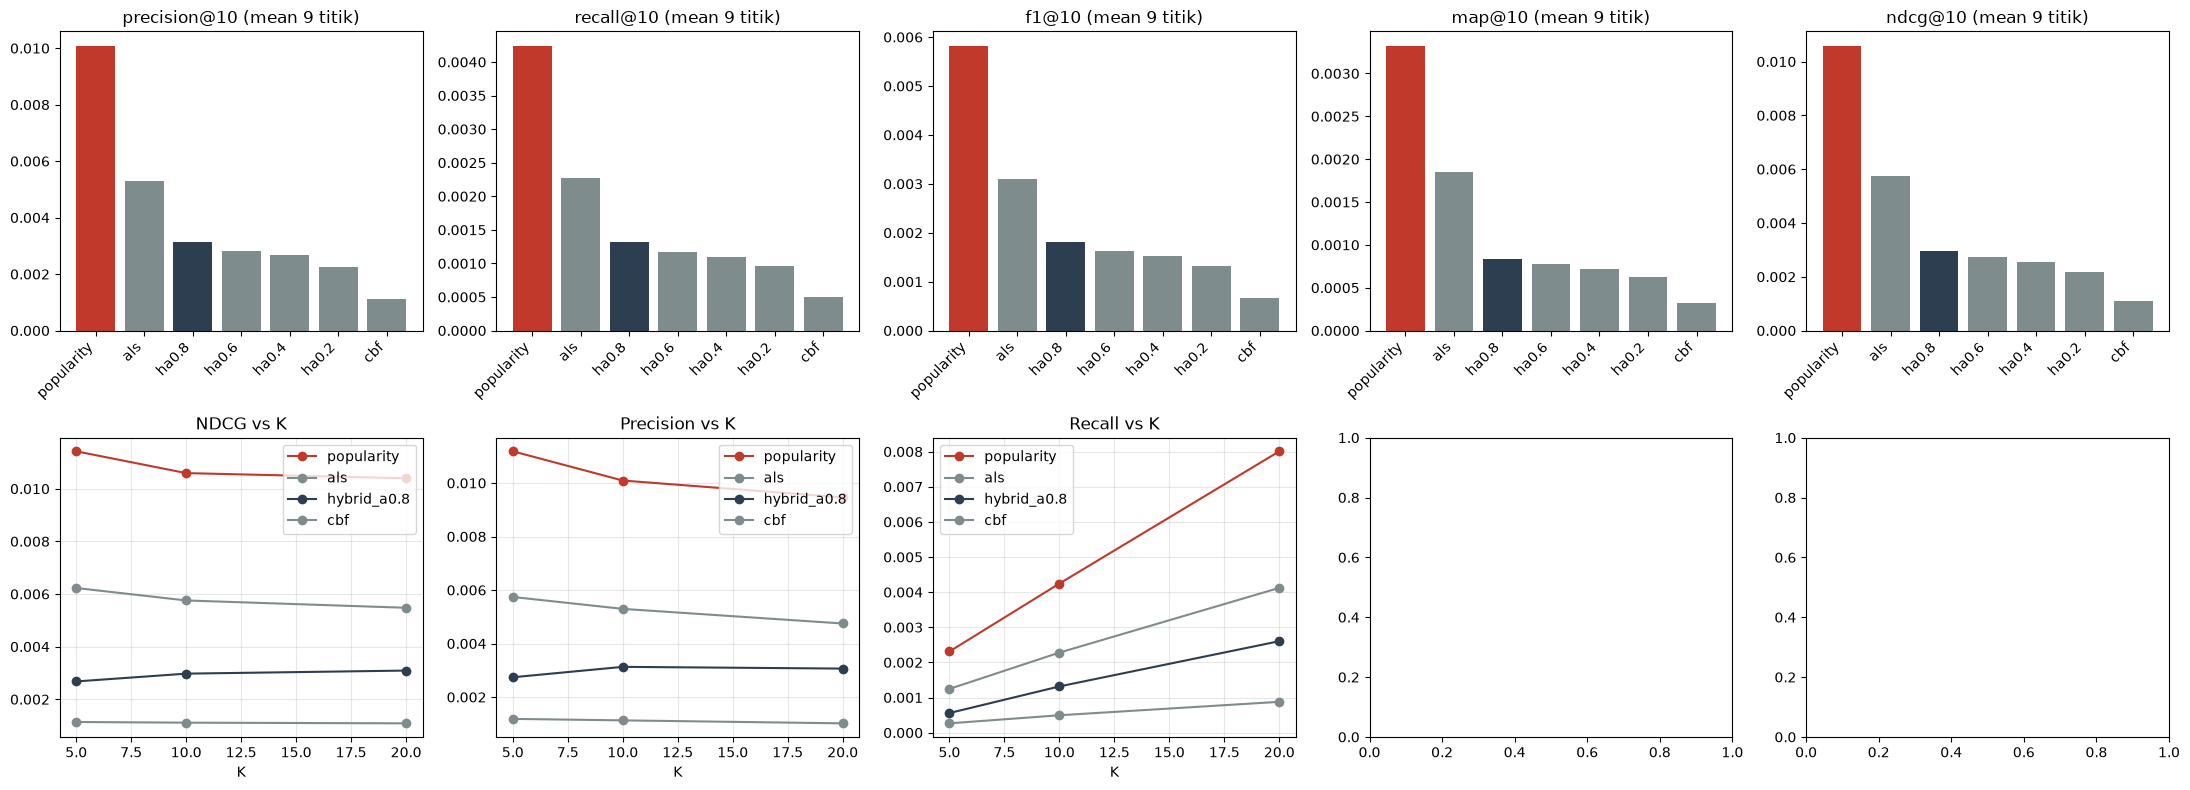

grafik -> docs/evidence/phase2/metric_comparison.png


In [7]:
SERVING = f"hybrid_a{SERVING_ALPHA}"
fig, axes = plt.subplots(2, 5, figsize=(22, 8))

order = ["popularity", "als", SERVING, "hybrid_a0.6", "hybrid_a0.4", "hybrid_a0.2", "cbf"]
colors = {s: ("#c0392b" if s == "popularity" else
              "#2c3e50" if s == SERVING else "#7f8c8d") for s in order}
assert set(order) == set(system_names), (set(order), set(system_names))

for j, m in enumerate(["precision", "recall", "f1", "map", "ndcg"]):
    ax = axes[0][j]
    sub = summary[(summary.metric == m) & (summary["K"] == 10)]
    vals = [sub[sub.system == s]["mean"].iloc[0] for s in order]
    print("order:", order); print("vals:", vals)
    assert len(vals) == len(order), (len(vals), len(order), m)
    ax.bar(range(len(order)), vals, color=[colors[s] for s in order])
    ax.set_title(f"{m}@10 (mean 9 titik)")
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([s.replace("hybrid_", "h") for s in order], rotation=45, ha="right")

ax = axes[1][0]
for s in ["popularity", "als", SERVING, "cbf"]:
    vals = [summary[(summary.system == s) & (summary.metric == "ndcg") & (summary["K"] == K)]["mean"].iloc[0] for K in K_GRID]
    ax.plot(K_GRID, vals, marker="o", label=s, color=colors.get(s))
ax.set_title("NDCG vs K"); ax.set_xlabel("K"); ax.legend(); ax.grid(alpha=.3)

ax = axes[1][1]
for s in ["popularity", "als", SERVING, "cbf"]:
    vals = [summary[(summary.system == s) & (summary.metric == "precision") & (summary["K"] == K)]["mean"].iloc[0] for K in K_GRID]
    ax.plot(K_GRID, vals, marker="o", label=s, color=colors.get(s))
ax.set_title("Precision vs K"); ax.set_xlabel("K"); ax.legend(); ax.grid(alpha=.3)

ax = axes[1][2]
for s in ["popularity", "als", SERVING, "cbf"]:
    vals = [summary[(summary.system == s) & (summary.metric == "recall") & (summary["K"] == K)]["mean"].iloc[0] for K in K_GRID]
    ax.plot(K_GRID, vals, marker="o", label=s, color=colors.get(s))
ax.set_title("Recall vs K"); ax.set_xlabel("K"); ax.legend(); ax.grid(alpha=.3)

plt.tight_layout()
plt.savefig(REPO / "docs/evidence/phase2/metric_comparison.png", dpi=120, bbox_inches="tight")
plt.show()
print("grafik -> docs/evidence/phase2/metric_comparison.png")

## 6. Cara membaca hasil (narasi)

**Yang diharapkan dan alasannya.** Interaksi korpus ini simulasi: generator
memilih item dengan skema power-law, artinya "popularitas" didefinisikan oleh
proses yang sama yang menciptakan data. Karena itu popularity hampir pasti
menang di semua metrik — ia membaca ulang aturan mainnya. Angka popularity di
sini adalah **referensi batas atas**, bukan bukti sistem lain gagal.

**Membaca tiap metrik pada hasil:**

- *Precision@K* menurun saat K membesar untuk semua sistem: slot tambahan
  diisi item yang makin tidak relevan. Perhatikan posisi relatif sistem tidak
  berubah antar K — peringkat kualitas stabil.
- *Recall@K* naik saat K membesar (lebih banyak slot = lebih banyak peluang
  hit). Recall di K=20 yang naik paling tajam justru milik popularity karena
  item populer menumpuk di peringkat atas.
- *F1@K* menunjukkan kompromi: sistem dengan recall tinggi tapi presisi rendah
  tidak lagi tampak dominan. Di korpus ini F1 mengurangi jarak popularity-ALS
  dibanding Recall, karena popularity mengorbankan presisi demi recall.
- *MAP@K* dan *NDCG@10* menghargai urutan. ALS lebih unggul di NDCG dibanding
  CBF karena faktor laten menempatkan hit lebih ke atas, bukan hanya
  menambah hit.
- **Hybrid α=0.8** (sistem yang dilayani web) berada di antara ALS dan CBF di
  hampir semua metrik: bobot 0.8 CF menariknya ke ALS, 0.2 CBF menambah
  sedikit keragaman. Validasi silang di bagian 3 menjamin peringkat hybrid di
  notebook ini persis peringkat yang dievaluasi resmi.

**Caveat yang wajib dibawa saat mengutip angka** (sama dengan
`models/indo_eval.json`):

1. Interaksi simulasi: popularity adalah batas atas, bukan kemenangan sistem.
2. Skala absolut kecil (NDCG ~0.01): katalog dev puluhan ribu item dengan
   ~24 item relevan per akun; yang bermakna adalah perbandingan antar sistem.
3. Semua sel memakai n=600 akun; jangan bandingkan sel dengan n berbeda tanpa
   menyebut n.

**Validasi silang adalah bagian dari hasil.** Bagian 3 membuktikan notebook
menghitung dengan protokol yang sama, sehingga tiga metrik tambahan
(Precision/F1 pada K lain) berdiri di atas fondasi yang sudah terkunci, bukan
angka baru tanpa jejak.


## Reproduksi

```bash
source venv/bin/activate
jupyter nbconvert --to notebook --execute notebooks/eval_metrik.ipynb --inplace
python -m pytest tests/phase2/test_metrics_ext.py -q
```

Waktu eksekusi sekitar 10-12 menit (9 titik x ~70 detik; sebagian besar di
TF-IDF transform dan 7 sistem x 600 akun).
